# Análise exploratória de dados — desperdício de alimentos
### Aula 11 · Atividade prática de EDA

**Dataset:** Messy Food Waste Prediction Dataset.  
**Fonte:** [competição no Kaggle](https://www.kaggle.com/competitions/messy-food-waste-prediction-dataset/data).  
**Arquivo analisado:** `train.csv` do ZIP fornecido nesta atividade.

**Objetivo:** investigar a qualidade dos dados e as associações entre características da operação e a quantidade de alimentos desperdiçada. O alvo, `food_waste_kg`, é **quantitativo contínuo**; portanto, um eventual problema de previsão seria de regressão.

O notebook segue o ciclo da aula: estrutura → ausentes → distribuições → tratamento → comparação antes/depois → relações → síntese. Cada etapa apresenta uma pergunta e uma discussão dos resultados.

**Como usar:** as células já estão executadas, com tabelas e gráficos salvos. Para reproduzir no Google Colab ou Jupyter, execute todas as células em ordem. O CSV original está incorporado de forma compactada; não é necessário acessar o Kaggle nem enviar outro arquivo. A célula de dados pode ficar recolhida.

**Escopo:** os resultados descrevem este arquivo. A página apresenta uma base destinada a exercícios de limpeza; não há documentação suficiente sobre amostragem ou coleta para generalizar os resultados a todos os refeitórios ou afirmar relações causais.

## 1. Perguntas que orientam a análise

1. Quais problemas de qualidade estão realmente presentes nos arquivos recebidos?
2. Como o desperdício se distribui? Média e mediana contam a mesma história?
3. Mais refeições servidas e maior desperdício anterior se associam a maior desperdício atual?
4. Dias com eventos especiais apresentam mais desperdício, inclusive por refeição?
5. Categoria do alimento, experiência da equipe e dia da semana diferenciam os resultados?
6. As conclusões mudam quando verificamos a influência dos extremos e de registros quase repetidos?

## 2. Bibliotecas e carregamento

In [1]:
import io
import base64
import zlib
import hashlib
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from IPython.display import display, Markdown
%matplotlib inline

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

COR_NEUTRA = "#b6b9c2"
COR_CONTEXTO = "#dfc5bd"
COR_DESTAQUE = "#382b4b"
COR_ALERTA = "#bd463d"
PALETA_EVENTO = {"Sem evento": COR_CONTEXTO, "Com evento": COR_DESTAQUE}
ORDEM_EVENTO = ["Sem evento", "Com evento"]
ALVO = "food_waste_kg"
QUANT = ["meals_served", "kitchen_staff", "temperature_C",
         "humidity_percent", "past_waste_kg", ALVO]
QUALI = ["day_of_week", "special_event", "staff_experience", "waste_category"]
ROTULOS = {"meals_served": "Refeições servidas", "kitchen_staff": "Equipe (pessoas)",
           "temperature_C": "Temperatura (°C)", "humidity_percent": "Umidade (%)",
           "past_waste_kg": "Desperdício anterior (kg)", ALVO: "Desperdício atual (kg)"}

def br(valor, casas=2):
    return f"{valor:,.{casas}f}".replace(",", "@").replace(".", ",").replace("@", ".")

def texto(s):
    display(Markdown(s))

def descritiva(dados):
    t = dados[QUANT].describe().T.rename(columns={"50%": "mediana"})
    t["variancia"] = dados[QUANT].var()
    t["IQR"] = dados[QUANT].quantile(.75) - dados[QUANT].quantile(.25)
    t["assimetria"] = dados[QUANT].skew()
    t["curtose_excesso"] = dados[QUANT].kurt()
    return t

def limites_iqr(serie):
    q1, q3 = serie.dropna().quantile([.25, .75])
    return q1 - 1.5 * (q3-q1), q3 + 1.5 * (q3-q1)

def mascara_iqr(serie):
    inferior, superior = limites_iqr(serie)
    return (serie < inferior) | (serie > superior)

display(pd.Series({"Python": sys.version.split()[0], "pandas": pd.__version__,
                   "NumPy": np.__version__, "SciPy": scipy.__version__,
                   "seaborn": sns.__version__, "matplotlib": matplotlib.__version__},
                  name="Versões da execução"))

Python        3.12.14
pandas          2.2.3
NumPy           2.3.5
SciPy          1.17.0
seaborn        0.13.2
matplotlib     3.10.8
Name: Versões da execução, dtype: object

In [2]:
#@title CSV original incorporado — não é necessário editar
CSV_COMPACTADO = (
    '...'
)
SHA256_ESPERADO = 'c2bedb198bf40cc6793921cdfe0573589923996b3347b3361561b114214b9adf'

In [3]:
csv_bytes = zlib.decompress(base64.b64decode(CSV_COMPACTADO))
assert hashlib.sha256(csv_bytes).hexdigest() == SHA256_ESPERADO, "CSV incorporado alterado."
df_original = pd.read_csv(io.BytesIO(csv_bytes))
print("Arquivo carregado: train.csv")
print(f"Dimensão: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas")
print("SHA-256:", hashlib.sha256(csv_bytes).hexdigest())
display(df_original.head())

Arquivo carregado: train.csv
Dimensão: 911 linhas × 12 colunas
SHA-256: c2bedb198bf40cc6793921cdfe0573589923996b3347b3361561b114214b9adf


,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.8873,45.3629,0,0,7.7406,intermediate,dairy,28.9465
1,1,2023-11-21,244,15,10.3179,64.4305,1,0,42.3118,NaN,MeAt,51.5491
2,4,2022-02-01,148,16,27.7143,69.0461,1,0,41.1843,Beginner,MeAt,53.0083
3,5,2023-03-19,157,19,19.1739,46.2928,6,0,41.5435,Beginner,MeAt,48.6215
4,6,2022-07-18,297,10,26.3752,79.7411,0,0,26.5251,Intermediate,MEAT,44.1570


**Por que usar apenas o treino?** Na inspeção do ZIP recebido, os 911 IDs e todas as variáveis explicativas de `test.csv` eram idênticos aos correspondentes do treino. `submission.csv` também reproduzia os valores do alvo, salvo arredondamento numérico. Esses arquivos não constituem novas observações e não foram concatenados. O notebook incorpora exclusivamente `train.csv`; nenhuma previsão foi tratada como observação adicional.

## 3. Princípio estrutural

**Pergunta:** que informação cada coluna representa e quais problemas aparecem na estrutura?

| Coluna | Papel na EDA | Significado |
|---|---|---|
| `ID` | Identificador | Identifica o registro; não entra nas correlações |
| `date` | Temporal | Data da medição |
| `meals_served` | Quantitativa discreta | Quantidade de refeições servidas |
| `kitchen_staff` | Quantitativa discreta | Número de pessoas na equipe |
| `temperature_C` | Quantitativa contínua | Temperatura em °C |
| `humidity_percent` | Quantitativa contínua | Umidade em percentual |
| `day_of_week` | Qualitativa cíclica | Dia da semana, 0 = segunda e 6 = domingo |
| `special_event` | Qualitativa binária | 0 = sem evento e 1 = com evento |
| `past_waste_kg` | Quantitativa contínua | Desperdício no ciclo anterior, em kg |
| `staff_experience` | Qualitativa ordinal | Experiência: iniciante, intermediário e especialista |
| `waste_category` | Qualitativa nominal | Tipo de alimento desperdiçado |
| `food_waste_kg` | Alvo contínuo | Desperdício atual, em kg |

Os códigos de evento e dia da semana são categorias, apesar de estarem armazenados como inteiros. O arquivo não identifica claramente estabelecimento ou turno; por isso, a unidade utilizada aqui é **registro**, sem pressupor que cada linha seja um refeitório independente.

In [4]:
df_original.info()
estrutura = pd.DataFrame({
    "tipo_lido": df_original.dtypes.astype(str),
    "valores_distintos": df_original.nunique(dropna=True),
    "ausentes": df_original.isna().sum(),
    "ausentes_%": 100 * df_original.isna().mean()
})
display(estrutura)
display(df_original.describe(include="all"))

datas = pd.to_datetime(df_original["date"], format="%Y-%m-%d", errors="coerce")
colunas_sem_id = df_original.columns.drop("ID").tolist()
chave_quase = df_original.columns.drop(["ID", "temperature_C"]).tolist()
auditoria_estrutura = pd.Series({
    "Duplicatas completas": int(df_original.duplicated().sum()),
    "IDs repetidos": int(df_original["ID"].duplicated().sum()),
    "Duplicatas sem ID": int(df_original.duplicated(subset=colunas_sem_id).sum()),
    "Datas inválidas": int(datas.isna().sum()),
    "Dias da semana divergentes da data": int((datas.dt.dayofweek != df_original.day_of_week).sum()),
    "Datas distintas": int(datas.nunique()),
    "Repetições ignorando apenas ID e temperatura": int(df_original.duplicated(subset=chave_quase).sum())
}, name="Quantidade")
display(auditoria_estrutura)
print("Período:", datas.min().strftime("%d/%m/%Y"), "a", datas.max().strftime("%d/%m/%Y"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                911 non-null    int64  
 1   date              911 non-null    object 
 2   meals_served      911 non-null    int64  
 3   kitchen_staff     911 non-null    int64  
 4   temperature_C     911 non-null    float64
 5   humidity_percent  911 non-null    float64
 6   day_of_week       911 non-null    int64  
 7   special_event     911 non-null    int64  
 8   past_waste_kg     911 non-null    float64
 9   staff_experience  747 non-null    object 
 10  waste_category    911 non-null    object 
 11  food_waste_kg     911 non-null    float64
dtypes: float64(4), int64(5), object(3)
memory usage: 85.5+ KB


,tipo_lido,valores_distintos,ausentes,ausentes_%
ID,int64,911,0,0.0000
date,object,867,0,0.0000
meals_served,int64,373,0,0.0000
kitchen_staff,int64,15,0,0.0000
temperature_C,float64,892,0,0.0000
humidity_percent,float64,867,0,0.0000
day_of_week,int64,7,0,0.0000
special_event,int64,2,0,0.0000
past_waste_kg,float64,867,0,0.0000
staff_experience,object,4,164,18.0022


,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
count,911.0000,911,911.0000,911.0000,911.0000,911.0000,911.0000,911.0000,911.0000,747,911,911.0000
unique,NaN,867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,5,NaN
top,NaN,2022-02-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Beginner,MEAT,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,191,210,NaN
mean,528.3271,NaN,375.4050,11.9001,22.1893,60.7613,3.0143,0.0856,27.0157,NaN,NaN,44.8427
std,305.0728,NaN,502.8127,4.2852,8.9224,17.3308,2.0095,0.2800,12.7742,NaN,NaN,27.9344
min,0.0000,NaN,100.0000,5.0000,-10.3722,30.1211,0.0000,0.0000,5.0084,NaN,NaN,10.8190
25%,266.0000,NaN,211.0000,8.0000,15.6846,46.0178,1.0000,0.0000,16.0914,NaN,NaN,32.8879
50%,531.0000,NaN,306.0000,12.0000,22.1150,61.6340,3.0000,0.0000,26.8541,NaN,NaN,41.1469
75%,795.5000,NaN,407.0000,15.0000,28.8043,75.7879,5.0000,0.0000,38.1499,NaN,NaN,50.0467


Duplicatas completas                              0
IDs repetidos                                     0
Duplicatas sem ID                                 0
Datas inválidas                                   0
Dias da semana divergentes da data                0
Datas distintas                                 867
Repetições ignorando apenas ID e temperatura     44
Name: Quantidade, dtype: int64

Período: 01/01/2022 a 26/09/2024


**Discussão.** Há **911 registros e 12 colunas**, com datas entre **01/01/2022 e 26/09/2024**. Não há IDs repetidos, duplicatas exatas, datas inválidas ou divergências entre a data e o dia da semana.

A descrição do Kaggle menciona possíveis números armazenados como texto. **No CSV recebido, refeições e equipe já são inteiros válidos.** Portanto, não há símbolos numéricos a remover nem justificativa para afirmar que esse problema foi corrigido nesta análise.

Existem **867 datas distintas** e **44 repetições adicionais quando se desconsideram ID e temperatura**: os pares têm todas as demais informações iguais, mas temperaturas ligeiramente diferentes. São registros quase repetidos, não duplicatas exatas. Eles permanecem na análise principal porque falta uma chave de coleta que permita decidir se são erros; uma análise de sensibilidade avaliará sua influência.

## 4. Dados ausentes e hipótese sobre o mecanismo

**Pergunta:** quais dados faltam, por que podem estar ausentes e qual tratamento é justificável?

,quantidade,percentual
ID,0,0.0000
date,0,0.0000
meals_served,0,0.0000
kitchen_staff,0,0.0000
temperature_C,0,0.0000
humidity_percent,0,0.0000
day_of_week,0,0.0000
special_event,0,0.0000
past_waste_kg,0,0.0000
staff_experience,164,18.0022


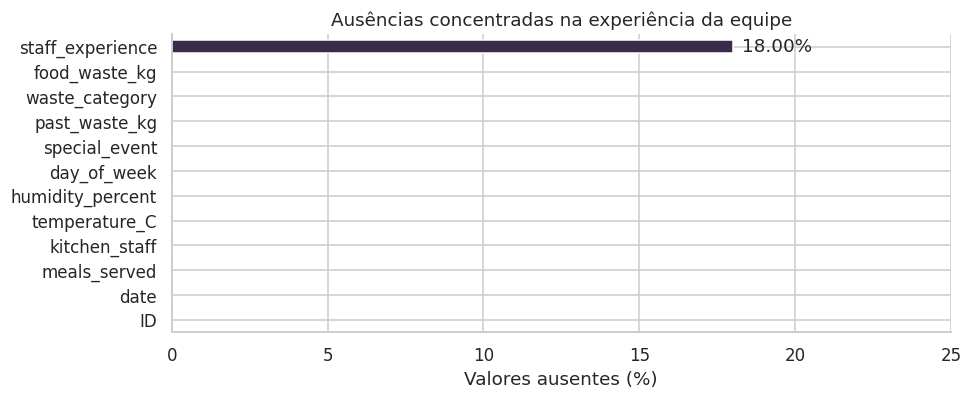

Evento (0=não; 1=sim),0,1
Experiência ausente,,
False,681,66
True,152,12


Qui-quadrado (com correção de Yates): p = 0.634681
Menor frequência esperada: 14.04


,count,mean,median
experiencia_ausente,,,
False,747,45.6935,41.4114
True,164,40.9672,39.7643


In [5]:
ausentes_antes = pd.DataFrame({"quantidade": df_original.isna().sum(),
                              "percentual": 100 * df_original.isna().mean()})
display(ausentes_antes)
fig, ax = plt.subplots(figsize=(9, 3.8))
ausentes_antes["percentual"].sort_values().plot.barh(color=COR_DESTAQUE, ax=ax)
ax.set(xlabel="Valores ausentes (%)", ylabel="", title="Ausências concentradas na experiência da equipe")
ax.set_xlim(0, 25)
for i, v in enumerate(ausentes_antes["percentual"].sort_values()):
    if v > 0:
        ax.text(v + .3, i, f"{v:.2f}%", va="center")
plt.tight_layout()
plt.show()

flag_ausente = df_original.staff_experience.isna()
cont_ausencia = pd.crosstab(flag_ausente.rename("Experiência ausente"),
                           df_original.special_event.rename("Evento (0=não; 1=sim)"))
chi_ausencia, p_ausencia, _, esperados_ausencia = stats.chi2_contingency(cont_ausencia)
display(cont_ausencia)
print(f"Qui-quadrado (com correção de Yates): p = {p_ausencia:.6g}")
print(f"Menor frequência esperada: {esperados_ausencia.min():.2f}")
display(df_original.assign(experiencia_ausente=flag_ausente)
        .groupby("experiencia_ausente")[ALVO].agg(["count", "mean", "median"]))

**Discussão.** Somente `staff_experience` tem ausências: **164 registros, equivalentes a 18,00%**. Como apenas uma coluna contém ausentes, não é possível investigar coocorrência de ausência entre duas colunas; uma matriz de correlação dos indicadores de ausência não acrescentaria informação.

O cruzamento com evento não apresentou evidência suficiente de associação (**p = 0,635**). Isso **não demonstra MCAR**. O preenchimento pode ter sido omitido arbitrariamente (hipótese MCAR), depender de alguma característica registrada da operação (MAR) ou depender da experiência não informada (MNAR). O mecanismo não pode ser identificado com segurança apenas por estes dados e a documentação disponível não esclarece sua origem.

**Decisão:** manter os 911 registros e preservar os valores ausentes. Criar apenas um rótulo de apresentação, **“Não informado”**, para tornar essas observações visíveis nos gráficos. Nas comparações entre níveis conhecidos de experiência, usar os 747 registros com essa informação. Não imputar a moda, pois isso atribuiria experiência sem evidência a 18% da base e aumentaria artificialmente a categoria intermediária. O alvo não possui ausências e não será imputado.

## 5. Princípio distribucional — retrato antes do tratamento

**Pergunta:** como se distribuem as medidas e quais estatísticas são mais representativas?

A curtose apresentada é a **curtose em excesso**: uma distribuição normal tem valor de referência zero. A descrição inclui média, mediana, variância, desvio padrão e intervalo interquartil (IQR).

,count,mean,mediana,std,variancia,IQR,min,max,assimetria,curtose_excesso
meals_served,911.0000,375.4050,306.0000,502.8130,252820.6280,196.0000,100.0000,4730.0000,6.5810,46.4090
kitchen_staff,911.0000,11.9000,12.0000,4.2850,18.3630,7.0000,5.0000,19.0000,0.0200,-1.1500
temperature_C,911.0000,22.1890,22.1150,8.9220,79.6090,13.1200,-10.3720,60.0000,0.1120,3.3910
humidity_percent,911.0000,60.7610,61.6340,17.3310,300.3570,29.7700,30.1210,89.9830,-0.0930,-1.1570
past_waste_kg,911.0000,27.0160,26.8540,12.7740,163.1810,22.0580,5.0080,49.8040,0.0160,-1.2050
food_waste_kg,911.0000,44.8430,41.1470,27.9340,780.3290,17.1590,10.8190,274.3290,4.9910,30.3800


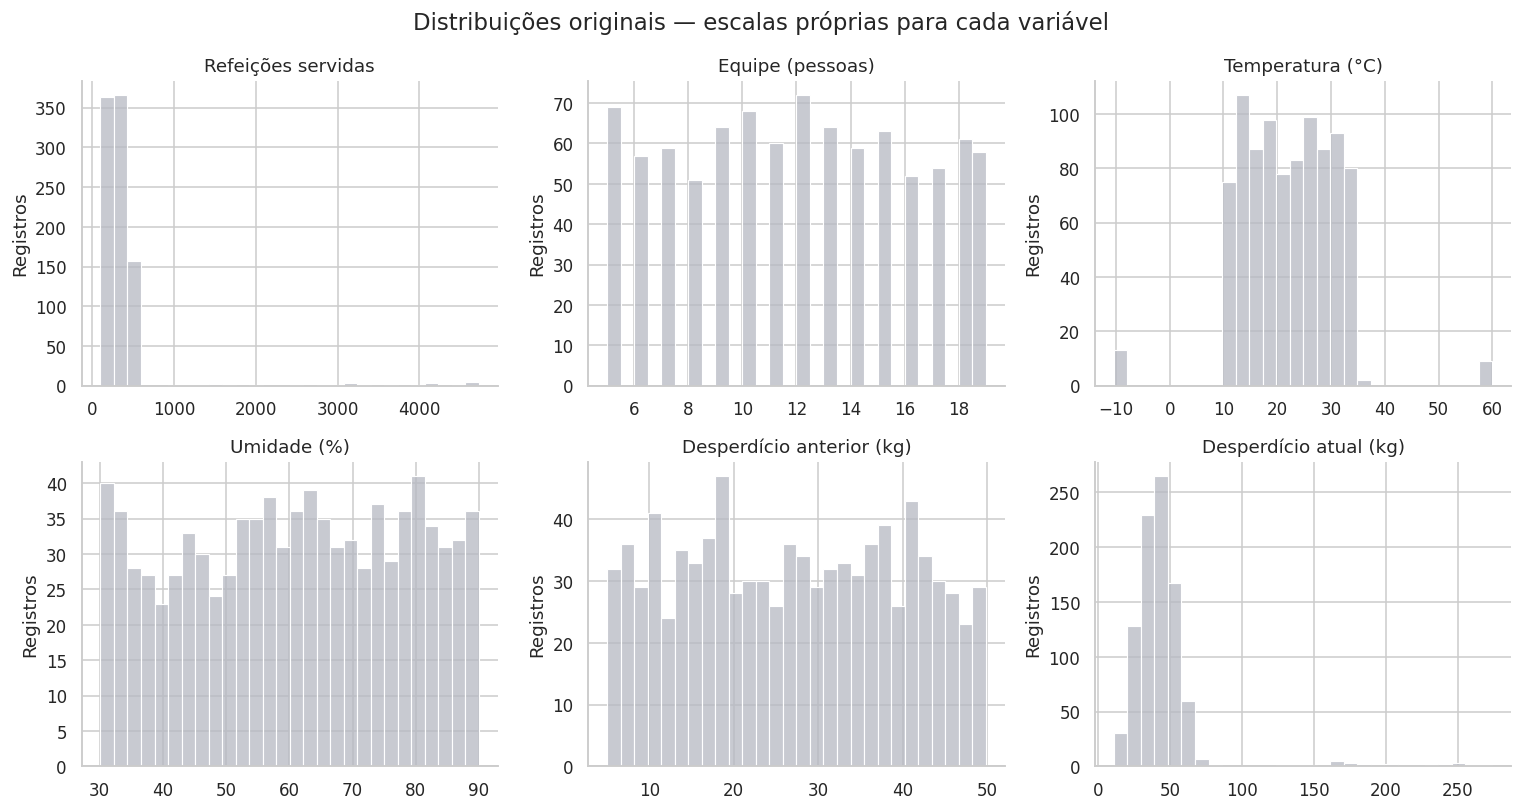

In [6]:
desc_antes = descritiva(df_original)
display(desc_antes[["count", "mean", "mediana", "std", "variancia", "IQR", "min", "max",
                    "assimetria", "curtose_excesso"]].round(3))
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.flat, QUANT):
    sns.histplot(df_original[col], bins=28, color=COR_NEUTRA, ax=ax)
    ax.set(title=ROTULOS[col], xlabel="", ylabel="Registros")
fig.suptitle("Distribuições originais — escalas próprias para cada variável", fontsize=15)
plt.tight_layout()
plt.show()

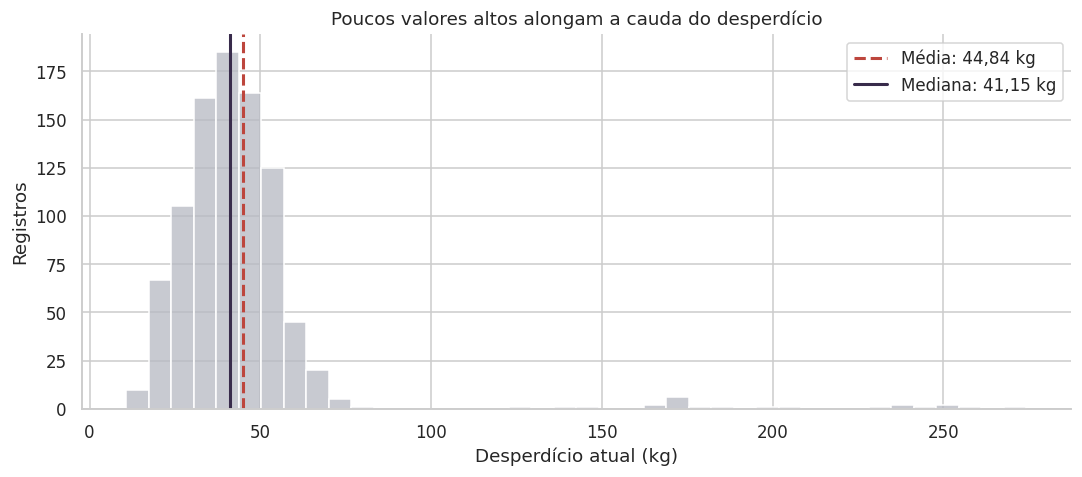

In [7]:
media = df_original[ALVO].mean()
mediana = df_original[ALVO].median()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(df_original[ALVO], bins=40, color=COR_NEUTRA, ax=ax)
ax.axvline(media, color=COR_ALERTA, ls="--", lw=2, label=f"Média: {br(media)} kg")
ax.axvline(mediana, color=COR_DESTAQUE, lw=2, label=f"Mediana: {br(mediana)} kg")
ax.set(title="Poucos valores altos alongam a cauda do desperdício", xlabel="Desperdício atual (kg)", ylabel="Registros")
ax.legend()
plt.tight_layout()
plt.show()

**Discussão.** O desperdício médio é **44,84 kg**, a mediana é **41,15 kg** e o máximo chega a **274,33 kg**. A diferença entre média e mediana, junto com a cauda direita, mostra a influência dos maiores valores. A mediana descreve melhor o centro dos registros, enquanto a média continua relevante para analisar o volume médio.

`meals_served` e `food_waste_kg` apresentam forte assimetria positiva (**6,58 e 4,99**) e curtose elevada (**46,41 e 30,38**). A temperatura é aproximadamente simétrica, mas tem curtose **3,39**, indicando que simetria sozinha não significa normalidade. As contagens de equipe são discretas e tampouco precisam seguir uma distribuição normal.

### 5.1 Normalidade: Shapiro–Wilk e QQ-plot

**Pergunta:** há evidência de que as quantitativas se afastam da distribuição normal?

Hipótese nula do Shapiro–Wilk: a amostra provém de uma distribuição normal. Usa-se α = 0,05. O teste complementa as visualizações; não determina sozinho todas as escolhas de análise.

,n,W,p_valor,rejeita_H0_5%
variavel,,,,
meals_served,911,0.3160,1.372e-49,True
kitchen_staff,911,0.9494,3.955e-17,True
temperature_C,911,0.9264,1.039e-20,True
humidity_percent,911,0.9558,6.142e-16,True
past_waste_kg,911,0.9556,5.595e-16,True
food_waste_kg,911,0.5216,4.461e-44,True


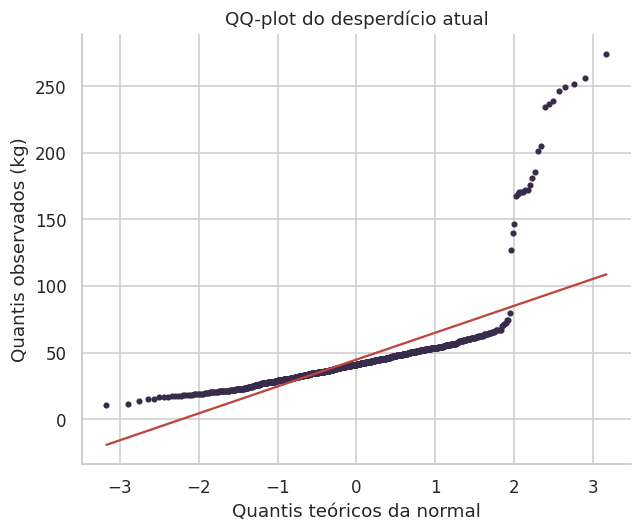

In [8]:
normalidade_antes = []
for col in QUANT:
    w, p = stats.shapiro(df_original[col].dropna())
    normalidade_antes.append({"variavel": col, "n": df_original[col].notna().sum(),
                             "W": w, "p_valor": p, "rejeita_H0_5%": p < .05})
normalidade_antes = pd.DataFrame(normalidade_antes).set_index("variavel")
display(normalidade_antes.style.format({"W": "{:.4f}", "p_valor": "{:.3e}"}))
fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(df_original[ALVO], dist="norm", plot=ax)
ax.get_lines()[0].set(markerfacecolor=COR_DESTAQUE, markeredgecolor=COR_DESTAQUE, markersize=3)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set(title="QQ-plot do desperdício atual", xlabel="Quantis teóricos da normal", ylabel="Quantis observados (kg)")
plt.tight_layout()
plt.show()

**Discussão.** Todas as seis quantitativas rejeitam a hipótese de normalidade ao nível de 5%. No desperdício, o afastamento da reta no QQ-plot é expressivo na cauda superior, coerente com o histograma e a assimetria. Com 911 registros o teste também pode detectar desvios pequenos, por isso a interpretação combina o teste e os gráficos. A normalidade marginal não é requisito para **calcular** Pearson; seus pressupostos inferenciais e sua sensibilidade a extremos são questões distintas.

## 6. Tratamento de inconsistências, ausentes e outliers

### 6.1 Padronização e validação de domínio

**Pergunta:** o que pode ser corrigido sem inventar valores?

Serão convertidas as datas, normalizadas as grafias das categorias e verificadas as regras de domínio. A transformação atua em uma cópia; `df_original` permanece intacto.

In [9]:
df = df_original.copy(deep=True)
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")
mudancas_categorias = []
for col in ["staff_experience", "waste_category"]:
    antes = df[col].copy()
    depois = antes.astype("string").str.strip().str.casefold().replace("", pd.NA)
    mudancas_categorias.append({"coluna": col, "categorias_antes": antes.nunique(),
                               "categorias_depois": depois.nunique(),
                               "celulas_padronizadas": int((antes.fillna("").astype(str) != depois.fillna("")).sum())})
    df[col] = depois
display(pd.DataFrame(mudancas_categorias).set_index("coluna"))

# Conversão defensiva: no arquivo recebido, já eram variáveis numéricas.
for col in QUANT + ["day_of_week", "special_event"]:
    convertido = pd.to_numeric(df[col], errors="coerce")
    assert not (df[col].notna() & convertido.isna()).any(), f"Rever valores não numéricos em {col}."
    df[col] = convertido

regras = {
    "Quantidade de refeições negativa": df.meals_served < 0,
    "Equipe negativa": df.kitchen_staff < 0,
    "Desperdício atual negativo": df[ALVO] < 0,
    "Desperdício anterior negativo": df.past_waste_kg < 0,
    "Umidade fora de 0 a 100%": ~df.humidity_percent.between(0, 100),
    "Refeições não inteiras": df.meals_served.mod(1) != 0,
    "Equipe não inteira": df.kitchen_staff.mod(1) != 0,
    "Dia fora dos códigos 0 a 6": ~df.day_of_week.isin(range(7)),
    "Evento fora dos códigos 0/1": ~df.special_event.isin([0, 1])
}
display(pd.Series({k: int(v.sum()) for k, v in regras.items()}, name="Violações"))

df["evento"] = pd.Categorical(df.special_event.map({0: "Sem evento", 1: "Com evento"}), categories=ORDEM_EVENTO)
map_exp = {"beginner": "Iniciante", "intermediate": "Intermediário", "expert": "Especialista"}
df["experiencia_label"] = df.staff_experience.map(map_exp).fillna("Não informado")
map_alimento = {"dairy": "Laticínios", "grains": "Grãos", "meat": "Carne", "vegetables": "Vegetais"}
df["alimento_label"] = df.waste_category.map(map_alimento)
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
df["dia_label"] = pd.Categorical(df.day_of_week.map(dict(enumerate(DIAS))), categories=DIAS, ordered=True)
df["experiencia_ausente"] = df.staff_experience.isna()
df["kg_por_refeicao"] = df[ALVO].div(df.meals_served.where(df.meals_served > 0))
assert df[ALVO].notna().all()

,categorias_antes,categorias_depois,celulas_padronizadas
coluna,,,
staff_experience,4,3,563
waste_category,5,4,731


Quantidade de refeições negativa    0
Equipe negativa                     0
Desperdício atual negativo          0
Desperdício anterior negativo       0
Umidade fora de 0 a 100%            0
Refeições não inteiras              0
Equipe não inteira                  0
Dia fora dos códigos 0 a 6          0
Evento fora dos códigos 0/1         0
Name: Violações, dtype: int64

**Discussão e decisões.** A experiência passa de **4 para 3 categorias conhecidas** ao reunir `Intermediate` e `intermediate`; alimentos passam de **5 para 4** ao reunir `MEAT` e `MeAt`. O rótulo “Não informado” aparece apenas na apresentação e não cria uma experiência conhecida. Não foram encontradas violações das regras numéricas verificadas.

A razão `kg_por_refeicao` é calculada somente para refeições positivas. Ela representa **kg desperdiçados por refeição servida**, não um percentual de comida desperdiçada: a base não informa o total de alimento preparado. Essa razão utiliza o alvo e, portanto, não deverá ser usada como preditora do próprio `food_waste_kg` em um modelo.

### 6.2 Detecção de outliers pela regra do IQR

**Pergunta:** valores raros são necessariamente erros?

A regra marca observações fora de `[Q1 − 1,5 × IQR; Q3 + 1,5 × IQR]`. Ela sinaliza pontos para investigação; não comprova que sejam inválidos.

,limite_inferior,limite_superior,quantidade,percentual
variavel,,,,
meals_served,-83.0000,701.0000,24,2.6340
kitchen_staff,-2.5000,25.5000,0,0.0000
temperature_C,-3.9950,48.4840,22,2.4150
humidity_percent,1.3630,120.4430,0,0.0000
past_waste_kg,-16.9960,71.2380,0,0.0000
food_waste_kg,7.1500,75.7850,24,2.6340


Registros sinalizados em pelo menos uma quantitativa: 47
União das sinalizações de refeições e desperdício: 25


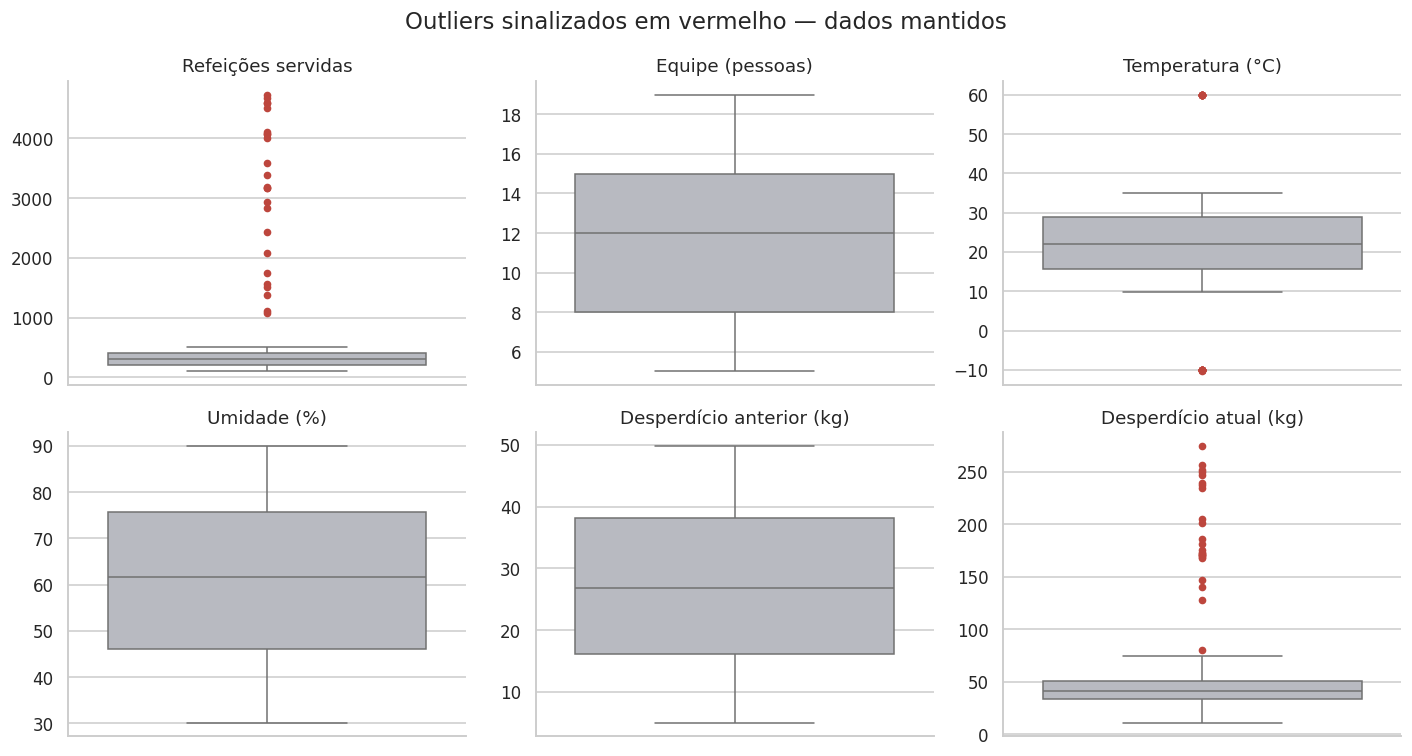

,ID,date,temperature_C
12,15,2022-01-25,-10.3722
102,115,2024-02-24,-10.0000
238,279,2023-03-06,-10.0000
345,401,2024-02-01,-10.0000
384,450,2022-03-15,-10.0000
463,539,2023-07-30,-10.0000
445,521,2023-01-29,-10.0000
407,477,2022-01-25,-10.0000
492,571,2022-04-04,-10.0000
768,889,2024-05-07,-10.0000


In [10]:
flags_iqr = pd.DataFrame({col: mascara_iqr(df[col]) for col in QUANT})
resumo_outliers = pd.DataFrame([
    {"variavel": col, "limite_inferior": limites_iqr(df[col])[0],
     "limite_superior": limites_iqr(df[col])[1], "quantidade": int(flags_iqr[col].sum()),
     "percentual": 100 * flags_iqr[col].mean()}
    for col in QUANT
]).set_index("variavel")
display(resumo_outliers.round(3))
print("Registros sinalizados em pelo menos uma quantitativa:", int(flags_iqr.any(axis=1).sum()))
print("União das sinalizações de refeições e desperdício:", int(flags_iqr[["meals_served", ALVO]].any(axis=1).sum()))

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, QUANT):
    sns.boxplot(y=df[col], color=COR_NEUTRA, ax=ax,
                flierprops={"markerfacecolor": COR_ALERTA, "markeredgecolor": COR_ALERTA, "markersize": 4})
    ax.set(title=ROTULOS[col], ylabel="", xlabel="")
fig.suptitle("Outliers sinalizados em vermelho — dados mantidos", fontsize=15)
plt.tight_layout()
plt.show()
display(df.loc[flags_iqr.temperature_C, ["ID", "date", "temperature_C"]].sort_values("temperature_C"))

**Discussão.** Há **24 outliers em refeições**, **24 em desperdício** e **22 em temperatura**; as outras quantitativas não apresentam outliers por essa regra. As sinalizações se sobrepõem: são **47 registros distintos** considerando todas as variáveis, e **25** na união de refeições e desperdício.

| Situação observada | Interpretação | Decisão |
|---|---|---|
| Até 4.730 refeições e 274,33 kg de desperdício | Valores estatisticamente extremos; podem refletir escala operacional ou erro de registro | Manter e avaliar influência; não dividir por 10 ou corrigir sem evidência |
| Temperaturas −10 °C, 60 °C e uma de −10,37 °C | Suspeitas para um ambiente de refeitório, mas o contexto da medição não está suficientemente descrito | Manter sinalizadas e recomendar investigação da fonte |
| Quantidades negativas, umidade fora de 0–100% ou códigos inválidos | Violações de domínio verificadas pelo código | Nenhum caso encontrado |
| Registros quase repetidos | Possível repetição de coleta; falta de chave de estabelecimento/turno | Manter na base principal e comparar com uma versão sem essas repetições |

Não há evidência suficiente para remover automaticamente os extremos. Essa é uma decisão de tratamento: **preservar a informação e documentar sua influência**, em vez de impor que todos os dados sigam uma distribuição normal.

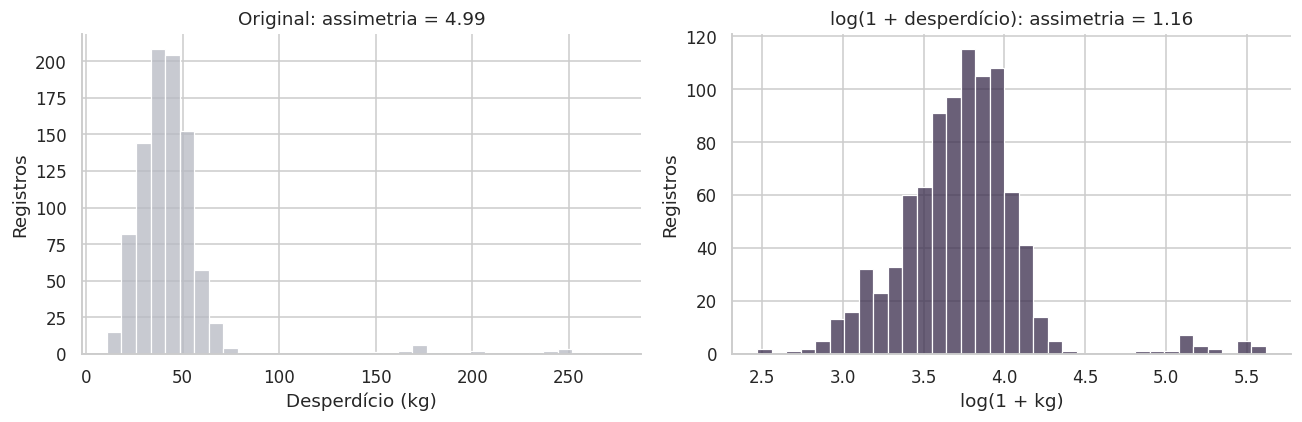

In [11]:
df["food_waste_log1p"] = np.log1p(df[ALVO])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[ALVO], bins=35, color=COR_NEUTRA, ax=axes[0])
sns.histplot(df.food_waste_log1p, bins=35, color=COR_DESTAQUE, ax=axes[1])
axes[0].set(title=f"Original: assimetria = {df[ALVO].skew():.2f}", xlabel="Desperdício (kg)")
axes[1].set(title=f"log(1 + desperdício): assimetria = {df.food_waste_log1p.skew():.2f}", xlabel="log(1 + kg)")
for ax in axes:
    ax.set_ylabel("Registros")
plt.tight_layout()
plt.show()

**Discussão.** A transformação `log1p` reduz a assimetria do desperdício de **4,99 para 1,16**, mas não torna automaticamente a distribuição normal. Ela é uma demonstração de alternativa para análises futuras. As comparações principais continuam em **kg**, preservando a interpretação original.

## 7. Estatística descritiva depois do tratamento

**Pergunta:** as escolhas de tratamento alteraram as distribuições ou esconderam ausências?

,count,mean,mediana,std,variancia,IQR,min,max,assimetria,curtose_excesso
meals_served,911.0000,375.4050,306.0000,502.8130,252820.6280,196.0000,100.0000,4730.0000,6.5810,46.4090
kitchen_staff,911.0000,11.9000,12.0000,4.2850,18.3630,7.0000,5.0000,19.0000,0.0200,-1.1500
temperature_C,911.0000,22.1890,22.1150,8.9220,79.6090,13.1200,-10.3720,60.0000,0.1120,3.3910
humidity_percent,911.0000,60.7610,61.6340,17.3310,300.3570,29.7700,30.1210,89.9830,-0.0930,-1.1570
past_waste_kg,911.0000,27.0160,26.8540,12.7740,163.1810,22.0580,5.0080,49.8040,0.0160,-1.2050
food_waste_kg,911.0000,44.8430,41.1470,27.9340,780.3290,17.1590,10.8190,274.3290,4.9910,30.3800


,media_antes,media_depois,mediana_antes,mediana_depois,assimetria_antes,assimetria_depois,curtose_antes,curtose_depois
meals_served,375.4050,375.4050,306.0000,306.0000,6.5811,6.5811,46.4091,46.4091
kitchen_staff,11.9001,11.9001,12.0000,12.0000,0.0202,0.0202,-1.1502,-1.1502
temperature_C,22.1893,22.1893,22.1150,22.1150,0.1119,0.1119,3.3912,3.3912
humidity_percent,60.7613,60.7613,61.6340,61.6340,-0.0932,-0.0932,-1.1569,-1.1569
past_waste_kg,27.0157,27.0157,26.8541,26.8541,0.0163,0.0163,-1.2051,-1.2051
food_waste_kg,44.8427,44.8427,41.1469,41.1469,4.9909,4.9909,30.3804,30.3804


,ausentes_antes,ausentes_depois
ID,0,0
date,0,0
meals_served,0,0
kitchen_staff,0,0
temperature_C,0,0
humidity_percent,0,0
day_of_week,0,0
special_event,0,0
past_waste_kg,0,0
staff_experience,164,164


Linhas antes: 911 | depois: 911 | removidas: 0
Maior alteração absoluta nas quantitativas: 0.0
Shapiro após tratamento do alvo: p = 4.461e-44


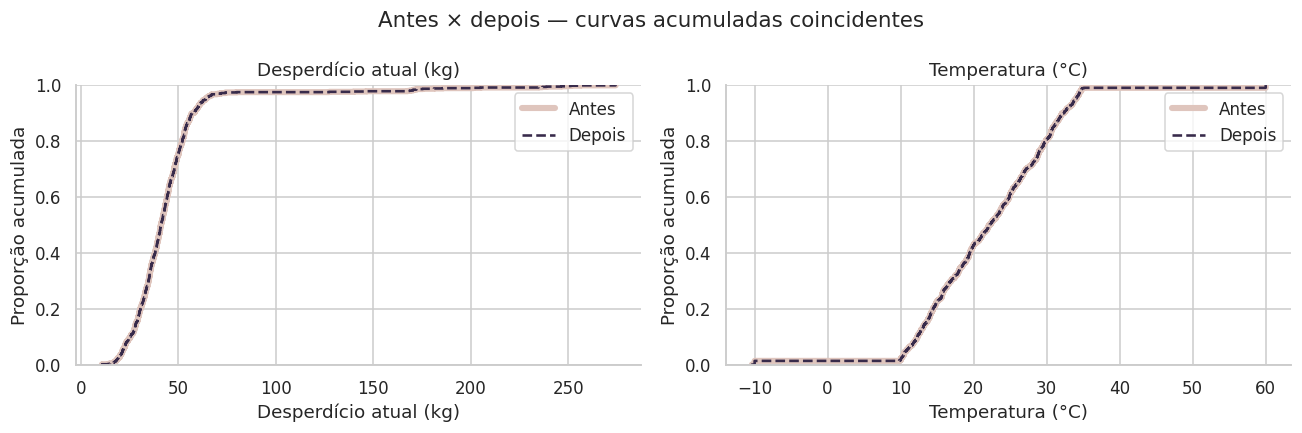

In [12]:
desc_depois = descritiva(df)
display(desc_depois[["count", "mean", "mediana", "std", "variancia", "IQR", "min", "max",
                     "assimetria", "curtose_excesso"]].round(3))
comparacao = pd.DataFrame({
    "media_antes": desc_antes["mean"], "media_depois": desc_depois["mean"],
    "mediana_antes": desc_antes["mediana"], "mediana_depois": desc_depois["mediana"],
    "assimetria_antes": desc_antes["assimetria"], "assimetria_depois": desc_depois["assimetria"],
    "curtose_antes": desc_antes["curtose_excesso"], "curtose_depois": desc_depois["curtose_excesso"]
})
display(comparacao.round(4))
display(pd.DataFrame({"ausentes_antes": df_original.isna().sum(),
                      "ausentes_depois": df[df_original.columns].isna().sum()}))
print(f"Linhas antes: {len(df_original)} | depois: {len(df)} | removidas: {len(df_original)-len(df)}")
print("Maior alteração absoluta nas quantitativas:", (df[QUANT] - df_original[QUANT]).abs().max().max())
print("Shapiro após tratamento do alvo: p =", f"{stats.shapiro(df[ALVO]).pvalue:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, [ALVO, "temperature_C"]):
    sns.ecdfplot(df_original[col], ax=ax, color=COR_CONTEXTO, linewidth=4, label="Antes")
    sns.ecdfplot(df[col], ax=ax, color=COR_DESTAQUE, linewidth=1.7, linestyle="--", label="Depois")
    ax.set(title=ROTULOS[col], xlabel=ROTULOS[col], ylabel="Proporção acumulada")
    ax.legend()
fig.suptitle("Antes × depois — curvas acumuladas coincidentes", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão.** As estatísticas numéricas e as curvas acumuladas permanecem **idênticas**: nenhuma linha foi removida e nenhum valor quantitativo foi alterado ou imputado. As 164 ausências continuam registradas na coluna de experiência. O ganho está na consistência das categorias e no tratamento temporal, não em uma mudança artificial da distribuição. A rejeição de normalidade também permanece. Essa comparação confirma o efeito esperado das decisões adotadas.

## 8. Princípio relacional

### 8.1 Frequências e desbalanceamento das categorias

**Pergunta:** todos os grupos têm representação semelhante?

**evento**

,frequencia,percentual
evento,,
Sem evento,833,91.4400
Com evento,78,8.5600


**experiencia_label**

,frequencia,percentual
experiencia_label,,
Intermediário,370,40.6100
Iniciante,191,20.9700
Especialista,186,20.4200
Não informado,164,18.0000


**alimento_label**

,frequencia,percentual
alimento_label,,
Carne,379,41.6000
Laticínios,180,19.7600
Vegetais,176,19.3200
Grãos,176,19.3200


**dia_label**

,frequencia,percentual
dia_label,,
Dom,133,14.6000
Sáb,133,14.6000
Qua,132,14.4900
Seg,131,14.3800
Qui,128,14.0500
Ter,127,13.9400
Sex,127,13.9400


,categorias,maior/menor,entropia_normalizada
evento,2.0000,10.6790,0.4220
experiencia_label,4.0000,2.2560,0.9570
alimento_label,4.0000,2.1530,0.9530
dia_label,7.0000,1.0470,1.0000


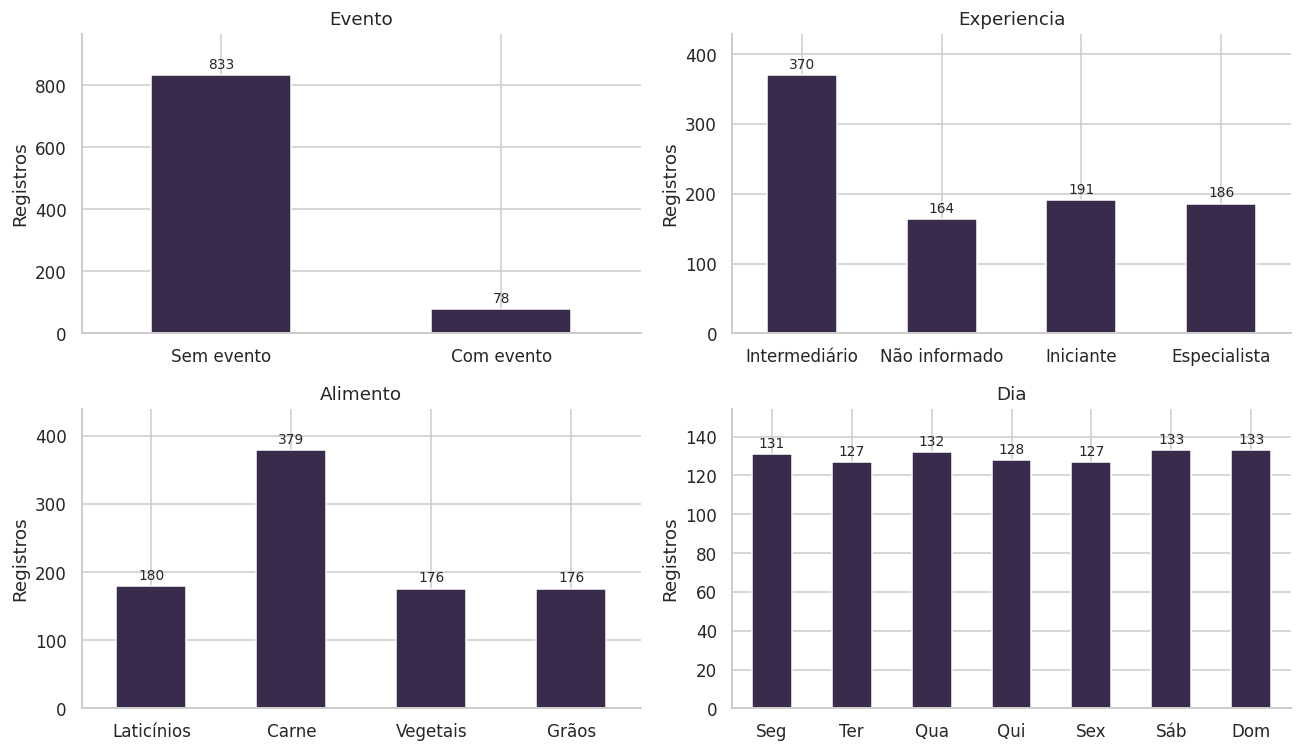

In [13]:
cats_apresentacao = ["evento", "experiencia_label", "alimento_label", "dia_label"]
def metricas_balanceamento(serie):
    counts = serie.value_counts(dropna=False)
    counts = counts[counts > 0]
    props = counts / counts.sum()
    k = len(counts)
    return {"categorias": k, "maior/menor": counts.max()/counts.min(),
            "entropia_normalizada": stats.entropy(props, base=2)/np.log2(k) if k > 1 else 0.0}

for col in cats_apresentacao:
    freq = df[col].value_counts(dropna=False)
    texto(f"**{col}**")
    display(pd.DataFrame({"frequencia": freq, "percentual": 100*freq/len(df)}).round(2))
display(pd.DataFrame({col: metricas_balanceamento(df[col]) for col in cats_apresentacao}).T.round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, cats_apresentacao):
    vc = df[col].value_counts(sort=False)
    vc.plot.bar(color=COR_DESTAQUE, ax=ax)
    ax.set(title=col.replace("_label", "").replace("_", " ").capitalize(), xlabel="", ylabel="Registros")
    ax.tick_params(axis="x", rotation=0)
    for i, v in enumerate(vc):
        ax.text(i, v + max(vc)*.025, str(v), ha="center", fontsize=9)
    ax.set_ylim(0, max(vc)*1.16)
plt.tight_layout()
plt.show()

**Discussão.** Eventos especiais aparecem em **78 registros (8,56%)**, contra **833 sem evento (91,44%)**: a razão de desbalanceamento é **10,68**. A categoria carne reúne **379 registros (41,60%)** após a padronização. Entre as experiências conhecidas, a categoria intermediária possui **370 registros**; os **164 não informados** devem ficar visíveis e não ser confundidos com um nível profissional.

O alvo é contínuo e não foi convertido em classes artificiais para medir “balanceamento do alvo”. A análise de representação se aplica aqui às categorias explicativas. Grupos menores, como eventos, geram estimativas menos estáveis e exigem atenção ao tamanho amostral.

### 8.2 Quantitativa × quantitativa: três correlações

**Pergunta:** quais medidas se associam ao desperdício e quanto os métodos concordam?

Pearson descreve associação **linear** e é sensível a extremos. Spearman e Kendall avaliam associação **monotônica por postos**. Diferenças entre os coeficientes podem resultar de extremos, da forma da relação ou de outros aspectos da distribuição; não provam automaticamente uma relação não linear.

,pearson,spearman,kendall
meals_served,0.8521,0.5577,0.3927
kitchen_staff,0.0072,0.0311,0.0222
temperature_C,-0.0159,0.0184,0.0115
humidity_percent,-0.0218,0.0577,0.0384
past_waste_kg,0.2608,0.6509,0.4692


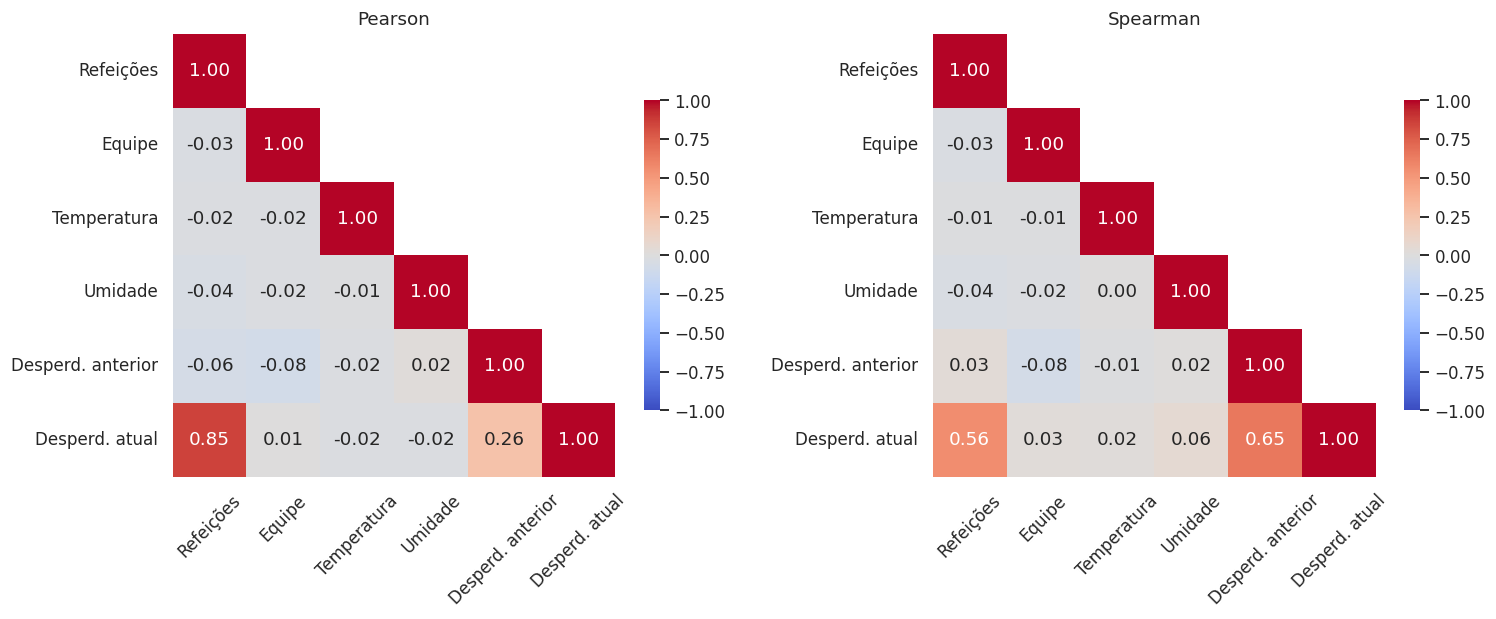

In [14]:
corrs = {metodo: df[QUANT].corr(method=metodo) for metodo in ["pearson", "spearman", "kendall"]}
comparacao_corr = pd.DataFrame({metodo: matriz[ALVO].drop(ALVO) for metodo, matriz in corrs.items()})
display(comparacao_corr.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
nomes_curtos = ["Refeições", "Equipe", "Temperatura", "Umidade", "Desperd. anterior", "Desperd. atual"]
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    matriz = corrs[metodo].copy()
    matriz.index = nomes_curtos
    matriz.columns = nomes_curtos
    sns.heatmap(matriz, mask=np.triu(np.ones_like(matriz, dtype=bool), k=1), annot=True,
                fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax,
                cbar_kws={"shrink": .7})
    ax.set_title(metodo.capitalize())
    ax.tick_params(axis="x", rotation=45)
    ax.grid(False)
plt.tight_layout()
plt.show()

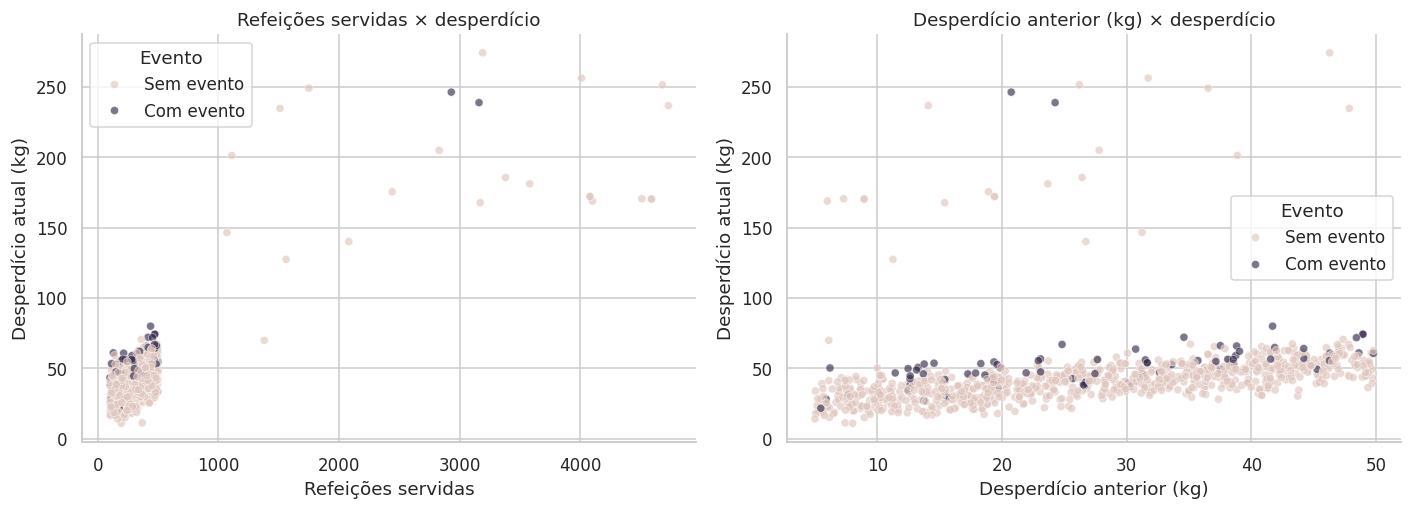

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col in zip(axes, ["meals_served", "past_waste_kg"]):
    sns.scatterplot(data=df, x=col, y=ALVO, hue="evento", palette=PALETA_EVENTO,
                    hue_order=ORDEM_EVENTO, alpha=.65, s=28, ax=ax)
    ax.set(xlabel=ROTULOS[col], ylabel=ROTULOS[ALVO], title=f"{ROTULOS[col]} × desperdício")
    ax.legend(title="Evento")
plt.tight_layout()
plt.show()

**Discussão.** Refeições e desperdício têm **Pearson = 0,852** e **Spearman = 0,558**: a associação é positiva, mas sua intensidade depende bastante da métrica. O gráfico mostra poucos registros com grande número de refeições e alto desperdício, capazes de afetar Pearson.

O desperdício anterior apresenta **Spearman = 0,651**, superior ao de refeições, mas **Pearson = 0,261**. A discrepância será verificada pela análise de sensibilidade. Tamanho da equipe, temperatura e umidade apresentam associações monotônicas fracas com o alvo nesta amostra. Isso não demonstra ausência de influência: relações condicionais, não monotônicas e diferenças de coleta podem não aparecer em uma correlação simples.

### 8.3 Quantitativa × qualitativa: eventos especiais

**Pergunta:** o desperdício é maior em registros com evento, mesmo levando em conta o número de refeições?

A comparação apresenta o desperdício total e a razão kg/refeição. A ECDF mostra, para cada valor no eixo horizontal, a proporção de registros até aquele valor, sem depender da escolha de intervalos do histograma.

,n,media_kg,mediana_kg,desvio_kg,mediana_refeicoes,media_das_razoes_kg_refeicao,mediana_kg_refeicao,razao_dos_totais_kg_refeicao
evento,,,,,,,,
Sem evento,833,43.8281,40.6049,27.2546,306.0000,0.1459,0.1339,0.1167
Com evento,78,55.6778,52.2877,32.6457,301.5000,0.1889,0.1638,0.1486


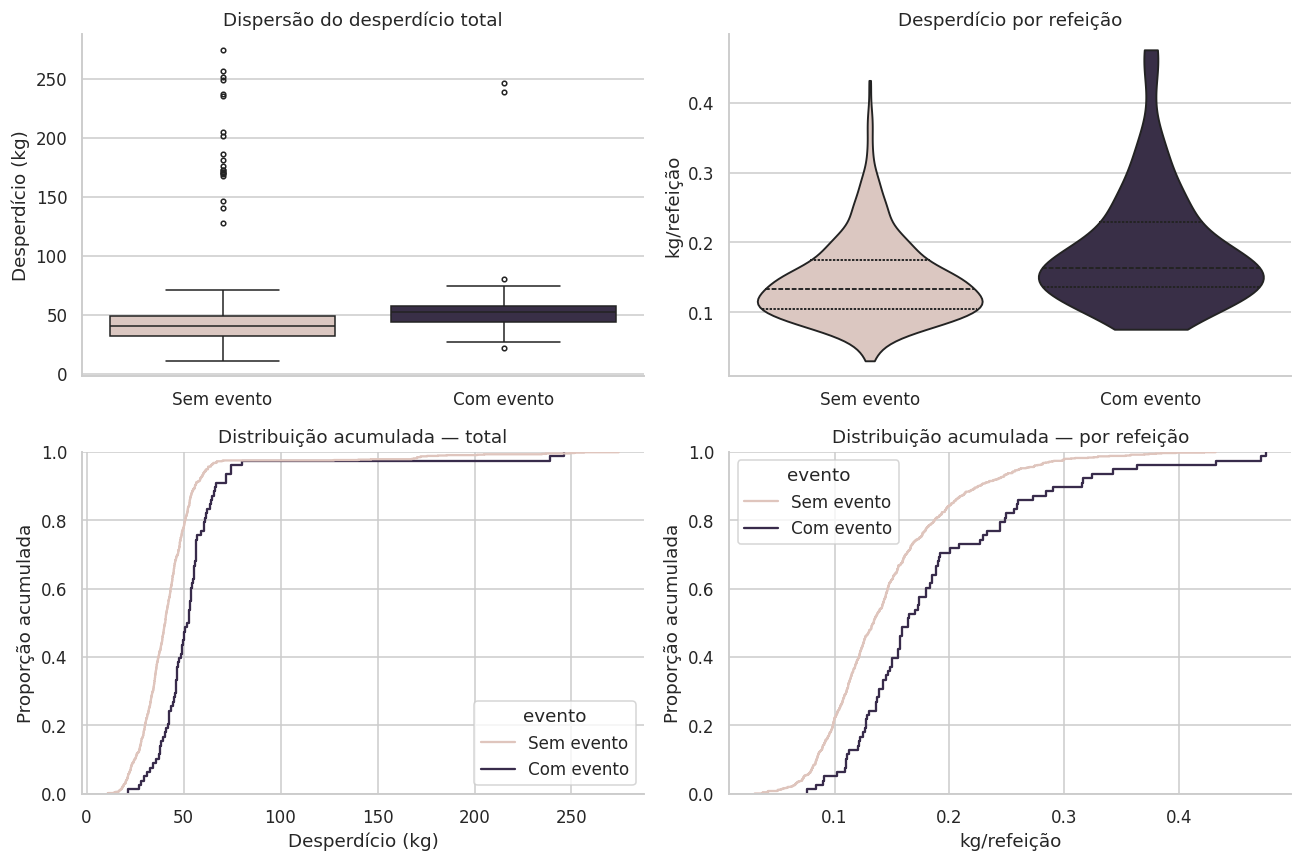

In [16]:
resumo_evento = df.groupby("evento", observed=True).agg(
    n=(ALVO, "size"), media_kg=(ALVO, "mean"), mediana_kg=(ALVO, "median"),
    desvio_kg=(ALVO, "std"), mediana_refeicoes=("meals_served", "median"),
    media_das_razoes_kg_refeicao=("kg_por_refeicao", "mean"),
    mediana_kg_refeicao=("kg_por_refeicao", "median"))
resumo_evento["razao_dos_totais_kg_refeicao"] = (
    df.groupby("evento", observed=True)[ALVO].sum() /
    df.groupby("evento", observed=True)["meals_served"].sum())
display(resumo_evento.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.boxplot(data=df, x="evento", y=ALVO, hue="evento", order=ORDEM_EVENTO,
            palette=PALETA_EVENTO, legend=False, ax=axes[0, 0], fliersize=3)
sns.violinplot(data=df, x="evento", y="kg_por_refeicao", hue="evento", order=ORDEM_EVENTO,
               palette=PALETA_EVENTO, legend=False, cut=0, inner="quartile", ax=axes[0, 1])
for ax, col in zip(axes[1], [ALVO, "kg_por_refeicao"]):
    sns.ecdfplot(data=df, x=col, hue="evento", hue_order=ORDEM_EVENTO, palette=PALETA_EVENTO, ax=ax)
    ax.set_ylabel("Proporção acumulada")
axes[0, 0].set(title="Dispersão do desperdício total", xlabel="", ylabel="Desperdício (kg)")
axes[0, 1].set(title="Desperdício por refeição", xlabel="", ylabel="kg/refeição")
axes[1, 0].set(title="Distribuição acumulada — total", xlabel="Desperdício (kg)")
axes[1, 1].set(title="Distribuição acumulada — por refeição", xlabel="kg/refeição")
plt.tight_layout()
plt.show()

In [17]:
# Mann–Whitney testa ordenação/distribuições; não é automaticamente um teste de medianas.
# Welch compara médias e aparece como contraste, pois é sensível a extremos e às condições amostrais.
testes_evento = []
for col in [ALVO, "kg_por_refeicao"]:
    com = df.loc[df.special_event == 1, col].dropna()
    sem = df.loc[df.special_event == 0, col].dropna()
    u, p_u = stats.mannwhitneyu(com, sem, alternative="two-sided")
    t, p_t = stats.ttest_ind(com, sem, equal_var=False)
    testes_evento.append({"variavel": col, "n_com": len(com), "n_sem": len(sem),
                          "U": u, "p_Mann_Whitney": p_u, "p_Welch": p_t,
                          "delta_Cliff_com_menos_sem": 2*u/(len(com)*len(sem))-1})
testes_evento = pd.DataFrame(testes_evento).set_index("variavel")
display(testes_evento.style.format({"p_Mann_Whitney": "{:.3e}", "p_Welch": "{:.3e}",
                                  "delta_Cliff_com_menos_sem": "{:.3f}"}))

,n_com,n_sem,U,p_Mann_Whitney,p_Welch,delta_Cliff_com_menos_sem
variavel,,,,,,
food_waste_kg,78,833,47793.000000,5.672e-12,2.558e-03,0.471
kg_por_refeicao,78,833,43719.000000,4.320e-07,2.934e-05,0.346


**Discussão.** Com evento, o desperdício médio é **55,68 kg**, contra **43,83 kg** sem evento (**27,04% maior**). As medianas são **52,29 e 40,60 kg**. As medianas de refeições são próximas: **301,5 e 306**.

A **média das razões por registro** é **0,1889 kg/refeição** com evento e **0,1459** sem evento (**29,42% maior**). Já a **razão dos totais**, que pondera pelo volume de refeições, é **0,1486 contra 0,1167 kg/refeição**. São medidas diferentes: a primeira dá o mesmo peso a cada registro, a segunda dá mais peso aos registros com mais refeições.

Mann–Whitney encontra evidência de diferença de distribuição tanto no total (**p ≈ 5,67 × 10⁻¹²**) quanto por refeição (**p ≈ 4,32 × 10⁻⁷**); Welch concorda ao comparar as médias. Os tamanhos de efeito são apresentados para complementar os p-valores. O teste por postos não elimina problemas de dependência entre observações.

**Interpretação:** eventos estão associados a maior desperdício neste arquivo, inclusive em relação ao volume servido. Isso não comprova que o evento cause o aumento; cardápio, duração da operação, tamanho das porções e outros fatores não observados podem contribuir. As comparações são exploratórias, com checagem de registros quase repetidos na seção 9.

### 8.4 Três ou mais grupos: alimentos, experiência e dia da semana

**Pergunta:** as diferenças visuais entre categorias sustentam uma diferença estatística?

Kruskal–Wallis avalia diferenças entre distribuições por postos. ANOVA é mostrada como contraste para médias; não é selecionada automaticamente a partir da normalidade marginal do alvo. Sem informação suficiente sobre forma das distribuições, não se interpreta Kruskal–Wallis simplesmente como teste de medianas.

**Desperdício por staff_experience (apenas categorias conhecidas)**

,count,mean,median,std
staff_experience,,,,
beginner,191,47.8540,42.2000,30.0420
expert,186,45.9240,41.4000,30.5570
intermediate,370,44.4620,40.9490,28.2310


**Desperdício por waste_category (apenas categorias conhecidas)**

,count,mean,median,std
waste_category,,,,
dairy,180,43.5550,41.5110,22.7530
grains,176,42.0010,40.3200,20.2960
meat,379,46.3050,41.2590,32.9670
vegetables,176,45.8530,42.6040,27.4450


**Desperdício por day_of_week (apenas categorias conhecidas)**

,count,mean,median,std
day_of_week,,,,
0,131,45.2440,43.2320,26.3930
1,127,42.3310,41.2330,18.3610
2,132,47.0650,40.7390,38.0500
3,128,43.7310,42.2150,24.3030
4,127,45.0810,39.7640,30.7460
5,133,45.2920,41.6100,28.6890
6,133,45.0350,42.1580,25.0700


,n_analisado,grupos,H,p_Kruskal_Wallis,p_ANOVA_contraste
agrupamento,,,,,
staff_experience,747,3,2.9387,0.2301,0.4268
waste_category,911,4,1.9315,0.5867,0.3248
day_of_week,911,7,2.1399,0.9064,0.9069


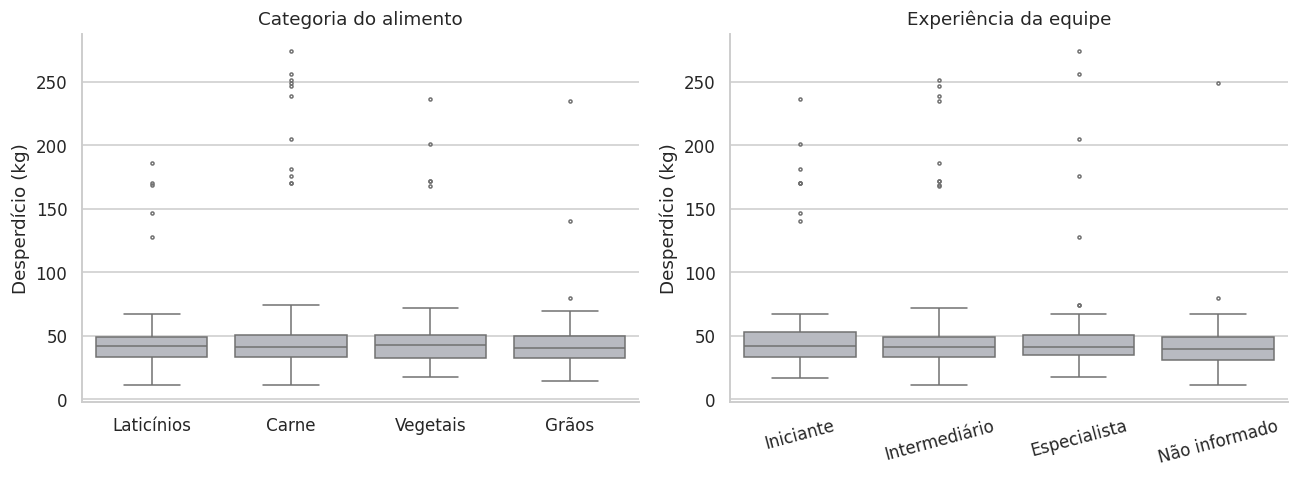

In [18]:
comparacoes_grupos = []
for col in ["staff_experience", "waste_category", "day_of_week"]:
    grupos = [g[ALVO].dropna().to_numpy() for _, g in df.groupby(col, observed=True, dropna=True)]
    h, p_kw = stats.kruskal(*grupos)
    f, p_anova = stats.f_oneway(*grupos)
    comparacoes_grupos.append({"agrupamento": col, "n_analisado": sum(map(len, grupos)),
                               "grupos": len(grupos), "H": h, "p_Kruskal_Wallis": p_kw,
                               "p_ANOVA_contraste": p_anova})
    texto(f"**Desperdício por {col} (apenas categorias conhecidas)**")
    display(df.groupby(col, observed=True, dropna=True)[ALVO].agg(["count", "mean", "median", "std"]).round(3))
comparacoes_grupos = pd.DataFrame(comparacoes_grupos).set_index("agrupamento")
display(comparacoes_grupos.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="alimento_label", y=ALVO, color=COR_NEUTRA, ax=axes[0], fliersize=2)
sns.boxplot(data=df, x="experiencia_label", y=ALVO,
            order=["Iniciante", "Intermediário", "Especialista", "Não informado"],
            color=COR_NEUTRA, ax=axes[1], fliersize=2)
axes[0].set(title="Categoria do alimento", xlabel="", ylabel="Desperdício (kg)")
axes[1].set(title="Experiência da equipe", xlabel="", ylabel="Desperdício (kg)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

**Discussão.** Kruskal–Wallis não encontra evidência suficiente de diferença no desperdício entre níveis conhecidos de experiência (**p = 0,230**), categorias de alimento (**p = 0,587**) ou dias da semana (**p = 0,906**). Isso não prova que as distribuições sejam iguais, nem que essas características sejam irrelevantes em outros contextos.

As medianas por alimento ficam aproximadamente entre **40,32 e 42,60 kg**. Nas experiências conhecidas, variam de **40,95 a 42,20 kg**. Não há base para afirmar que maior experiência reduza desperdício progressivamente. O grupo “Não informado” aparece no gráfico para transparência, mas **não entra como nível de experiência no teste**, que utiliza 747 registros. Não são realizados testes pós-hoc, pois o teste global não indicou diferença.

### 8.5 Qualitativa × qualitativa: categoria do alimento e evento

**Pergunta:** a composição das categorias de alimento difere entre registros com e sem evento?

evento,Sem evento,Com evento
alimento_label,,
Carne,345,34
Grãos,160,16
Laticínios,168,12
Vegetais,160,16


Qui-quadrado = 1.0327 | gl = 3 | p = 0.793346
Menor frequência esperada = 15.07 | V de Cramér = 0.0337


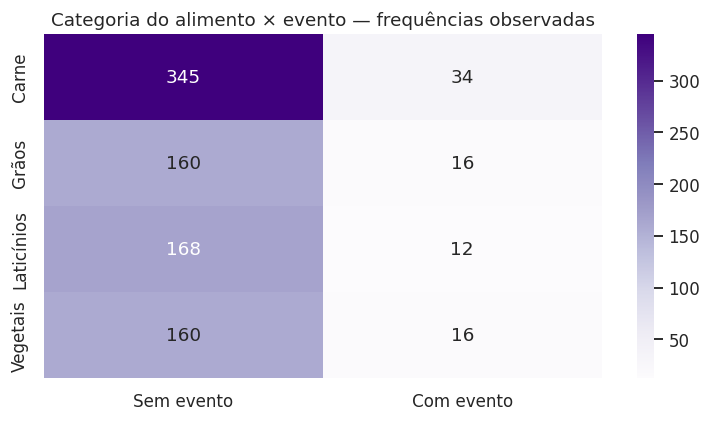

In [19]:
contingencia = pd.crosstab(df.alimento_label, df.evento)
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)
v_cramer = np.sqrt(chi2 / (contingencia.to_numpy().sum() * min(np.array(contingencia.shape)-1)))
display(contingencia)
print(f"Qui-quadrado = {chi2:.4f} | gl = {gl} | p = {p_chi2:.6f}")
print(f"Menor frequência esperada = {esperado.min():.2f} | V de Cramér = {v_cramer:.4f}")
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(contingencia, annot=True, fmt="d", cmap="Purples", ax=ax)
ax.set(title="Categoria do alimento × evento — frequências observadas", xlabel="", ylabel="")
ax.grid(False)
plt.tight_layout()
plt.show()

**Discussão.** A menor frequência esperada é maior que 5, condição adequada para a aproximação do qui-quadrado nesta tabela. O resultado (**p = 0,793; V de Cramér ≈ 0,034**) não fornece evidência de associação entre essas duas categorias. Isso ajuda a contextualizar a comparação de eventos, mas não controla simultaneamente os demais fatores e não demonstra independência em toda a população.

### 8.6 Representatividade e limites de fairness

**Pergunta:** é possível avaliar justiça entre grupos protegidos neste conjunto?

Não há atributos demográficos, informações de trabalhadores individuais ou previsões de um modelo. Portanto, **não é possível avaliar justiça algorítmica por grupos protegidos** com esta EDA. O que se pode avaliar é a representação dos grupos operacionais: apenas 8,56% dos registros têm evento e 18,00% não informam a experiência. Essas limitações devem ser lembradas ao comparar grupos ou propor um modelo futuro. Diferenças descritivas entre grupos não constituem, sozinhas, evidência de discriminação.

## 9. Análise de sensibilidade e pontos incomuns em conjunto

### 9.1 A influência dos valores extremos

**Pergunta:** a relação entre refeições e desperdício depende de poucos registros?

O recorte a seguir exclui os **25 registros** sinalizados pelo IQR em refeições **ou** desperdício. Ele é usado exclusivamente como análise de sensibilidade, e não como uma base “correta”. Selecionar observações pelo alvo pode alterar relações por construção; a comparação mede a sensibilidade ao recorte, não determina qual coeficiente representa a população.

,base,n,variavel,Pearson,Spearman
0,Completa,911,meals_served,0.8521,0.5577
1,Completa,911,past_waste_kg,0.2608,0.6509
2,Sem extremos de refeições/alvo,886,meals_served,0.5260,0.5198
3,Sem extremos de refeições/alvo,886,past_waste_kg,0.6998,0.7011


,count,mean,median
evento,,,
Sem evento,811,39.9270,40.0000
Com evento,75,50.3690,50.6400


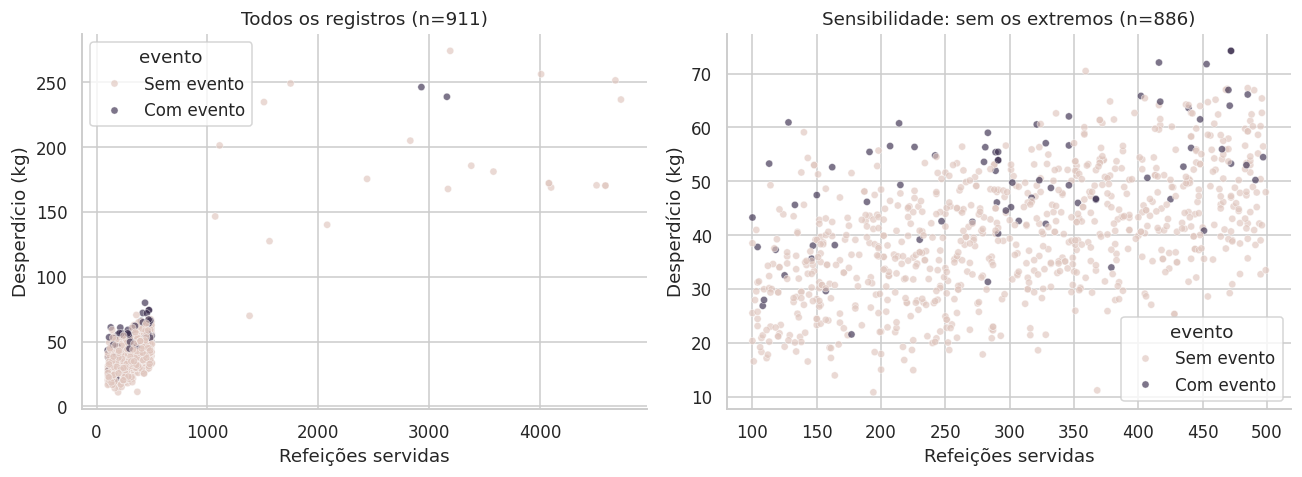

In [20]:
flag_volume = flags_iqr[["meals_served", ALVO]].any(axis=1)
df_sem_extremos = df.loc[~flag_volume].copy()
sens_corr = []
for nome, base in [("Completa", df), ("Sem extremos de refeições/alvo", df_sem_extremos)]:
    for var in ["meals_served", "past_waste_kg"]:
        sens_corr.append({"base": nome, "n": len(base), "variavel": var,
                          "Pearson": base[var].corr(base[ALVO], method="pearson"),
                          "Spearman": base[var].corr(base[ALVO], method="spearman")})
display(pd.DataFrame(sens_corr).round(4))
display(df_sem_extremos.groupby("evento", observed=True)[ALVO].agg(["count", "mean", "median"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (nome, base) in zip(axes, [("Todos os registros (n=911)", df),
                                  ("Sensibilidade: sem os extremos (n=886)", df_sem_extremos)]):
    sns.scatterplot(data=base, x="meals_served", y=ALVO, hue="evento", palette=PALETA_EVENTO,
                    alpha=.65, s=22, ax=ax)
    ax.set(title=nome, xlabel="Refeições servidas", ylabel="Desperdício (kg)")
plt.tight_layout()
plt.show()

**Discussão.** Para refeições e desperdício, **Pearson cai de 0,852 para 0,526**, enquanto **Spearman muda de 0,558 para 0,520**. A associação positiva permanece, mas os registros extremos elevam fortemente sua intensidade linear na base completa. As escalas dos dois painéis diferem para permitir inspecionar o recorte.

Para desperdício anterior e atual, os dois coeficientes ficam próximos de **0,70** no recorte, explicando por que olhar somente Pearson na base completa perderia parte importante da relação. A média de desperdício também permanece maior com evento: **50,37 contra 39,93 kg**. Não é necessário apagar os extremos para relatar esses achados com transparência.

### 9.2 Registros quase repetidos

**Pergunta:** a repetição de informações, exceto temperatura e ID, muda os principais achados?

In [21]:
# Chave de auditoria inclui o alvo; serve apenas à checagem desta EDA.
# Não é regra automática de deduplicação para um futuro modelo.
chave_quase = [c for c in df_original.columns if c not in ["ID", "temperature_C"]]
flag_quase = df.duplicated(subset=chave_quase, keep=False)
display(df.loc[flag_quase, ["ID", "date", "temperature_C", "meals_served", ALVO]]
        .sort_values(["date", "ID"]).head(10))
df_sem_quase = df.sort_values("ID").drop_duplicates(subset=chave_quase, keep="first")
sens_quase = []
for nome, base in [("Completa", df), ("Um registro por combinação auditada", df_sem_quase)]:
    com = base.loc[base.special_event == 1, ALVO]
    sem = base.loc[base.special_event == 0, ALVO]
    sens_quase.append({"base": nome, "n": len(base),
                       "rho_refeicoes": base.meals_served.corr(base[ALVO], method="spearman"),
                       "rho_passado": base.past_waste_kg.corr(base[ALVO], method="spearman"),
                       "p_evento_Mann_Whitney": stats.mannwhitneyu(com, sem, alternative="two-sided").pvalue})
sens_quase = pd.DataFrame(sens_quase).set_index("base")
display(sens_quase.style.format({"rho_refeicoes": "{:.4f}", "rho_passado": "{:.4f}",
                                "p_evento_Mann_Whitney": "{:.3e}"}))

,ID,date,temperature_C,meals_served,food_waste_kg
341,397,2022-01-01,31.9768,202,39.9011
364,427,2022-01-01,32.3188,202,39.9011
171,201,2022-01-02,10.0925,448,53.2034
849,983,2022-01-02,10.1286,448,53.2034
141,162,2022-01-03,30.4987,370,61.3754
656,764,2022-01-03,30.7597,370,61.3754
47,50,2022-01-04,15.7402,206,32.4411
99,112,2022-01-04,15.7156,206,32.4411
346,405,2022-01-05,32.4403,171,33.0406
773,899,2022-01-05,32.7175,171,33.0406


,n,rho_refeicoes,rho_passado,p_evento_Mann_Whitney
base,,,,
Completa,911,0.5577,0.6509,5.672e-12
Um registro por combinação auditada,867,0.5582,0.6554,2.889e-11


**Discussão.** Manter apenas o menor ID em cada combinação quase repetida produz **867 registros**. Spearman entre refeições e desperdício fica **0,558**, e entre desperdício anterior e atual fica **0,655**; a associação entre evento e desperdício permanece (**p ≈ 2,89 × 10⁻¹¹**). Assim, os principais achados não dependem dessas 44 repetições adicionais.

Essa verificação não garante independência das observações: podem existir relações temporais ou operacionais que a base não identifica. Os p-valores são exploratórios e não substituem um desenho de coleta conhecido. A base principal permanece com 911 registros.

### 9.3 Um ponto pode ser incomum apenas na combinação de variáveis?

Para visualizar desvios em relação ao número de refeições, ajusta-se uma reta robusta de **Theil–Sen** e aplica-se a regra do IQR aos resíduos. É um diagnóstico exploratório de duas variáveis; não se trata de um modelo de previsão validado nem de uma prova de erro.

Resíduos sinalizados pelo IQR: 17
Sinalizados sem serem outliers univariados de refeições/alvo: 1


,ID,date,meals_served,past_waste_kg,special_event,food_waste_kg
87,99,2023-04-13,368,7.4198,0,11.1813


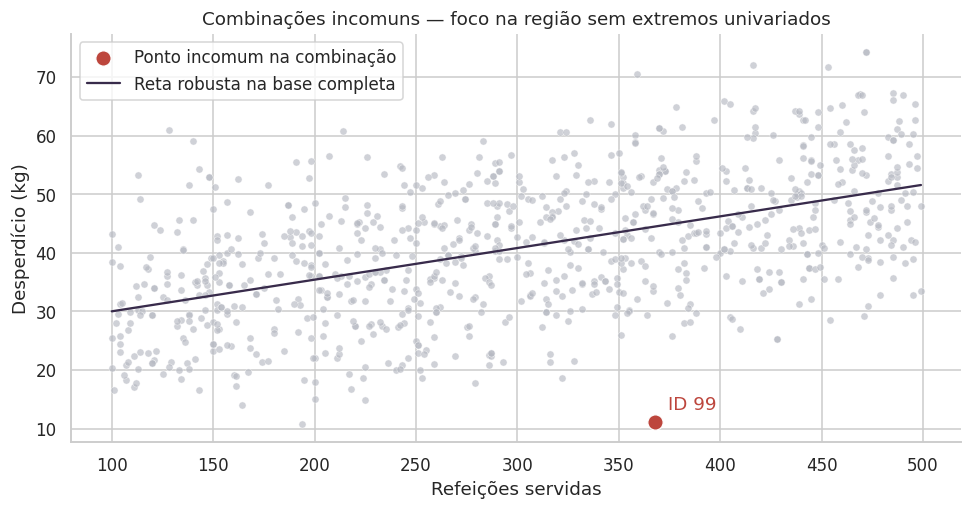

In [22]:
incl, intercepto, _, _ = stats.theilslopes(df[ALVO], df.meals_served)
residuos = df[ALVO] - (intercepto + incl * df.meals_served)
flag_residuo = mascara_iqr(residuos)
flag_apenas_conjunto = flag_residuo & ~flag_volume
print("Resíduos sinalizados pelo IQR:", int(flag_residuo.sum()))
print("Sinalizados sem serem outliers univariados de refeições/alvo:", int(flag_apenas_conjunto.sum()))
display(df.loc[flag_apenas_conjunto,
               ["ID", "date", "meals_served", "past_waste_kg", "special_event", ALVO]])
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.scatterplot(data=df.loc[~flag_volume], x="meals_served", y=ALVO, color=COR_NEUTRA,
                alpha=.65, s=22, ax=ax)
sns.scatterplot(data=df.loc[flag_apenas_conjunto], x="meals_served", y=ALVO,
                color=COR_ALERTA, s=100, ax=ax, label="Ponto incomum na combinação")
xx = np.linspace(df.loc[~flag_volume, "meals_served"].min(), df.loc[~flag_volume, "meals_served"].max(), 100)
ax.plot(xx, intercepto + incl*xx, color=COR_DESTAQUE, label="Reta robusta na base completa")
for _, linha in df.loc[flag_apenas_conjunto].iterrows():
    ax.annotate(f"ID {int(linha.ID)}", (linha.meals_served, linha[ALVO]),
                xytext=(8, 8), textcoords="offset points", color=COR_ALERTA)
ax.set(title="Combinações incomuns — foco na região sem extremos univariados", xlabel="Refeições servidas", ylabel="Desperdício (kg)")
ax.legend()
plt.tight_layout()
plt.show()

**Discussão.** O **ID 99** não é outlier univariado de refeições nem de desperdício, mas se destaca na combinação: **368 refeições e 11,18 kg** de desperdício. Seu desperdício anterior também é baixo (**7,42 kg**), o que ajuda a contextualizar o registro e mostra a utilidade de observar uma terceira variável. Ele é mantido: a reta descreve apenas uma tendência e não considera todas as características que podem explicar o resultado.

## 10. Análise multivariada

**Pergunta:** observar várias variáveis em conjunto muda a interpretação das relações?

O correlograma integra distribuições na diagonal, dispersões abaixo e correlações de Spearman acima. São selecionadas quatro variáveis para manter a legibilidade; a matriz da seção 8.2 já abrange todas as seis quantitativas.

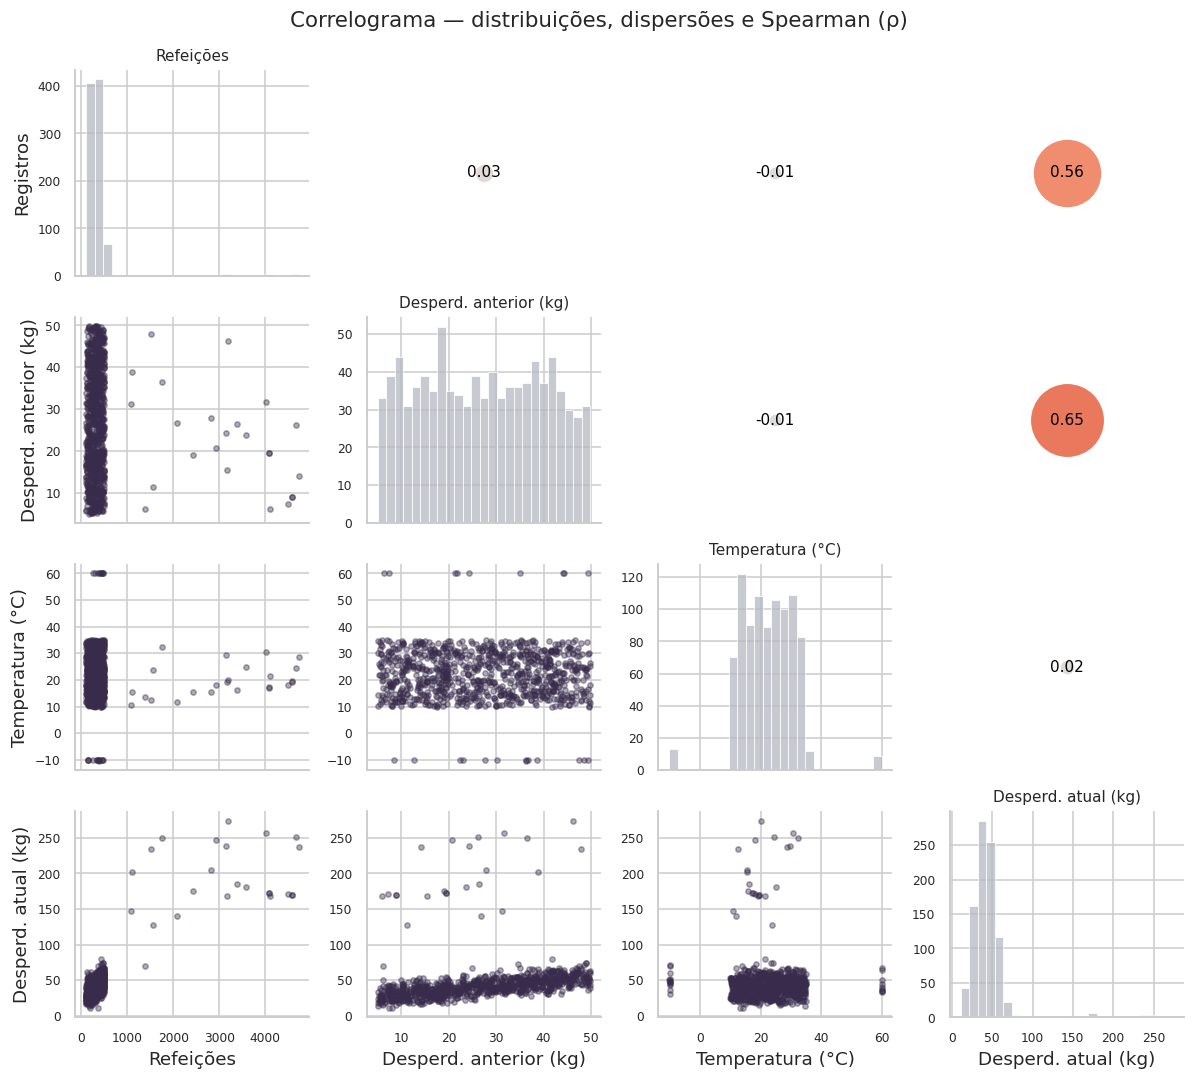

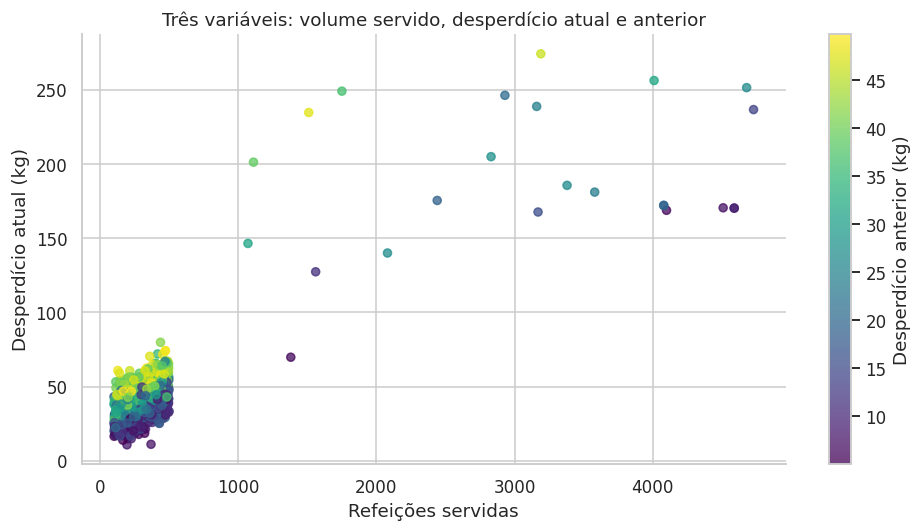

In [23]:
SELECAO = ["meals_served", "past_waste_kg", "temperature_C", ALVO]
curtos = {"meals_served": "Refeições", "past_waste_kg": "Desperd. anterior (kg)",
          "temperature_C": "Temperatura (°C)", ALVO: "Desperd. atual (kg)"}
fig, axes = plt.subplots(4, 4, figsize=(11, 10))
for i, var_y in enumerate(SELECAO):
    for j, var_x in enumerate(SELECAO):
        ax = axes[i, j]
        if i == j:
            sns.histplot(df[var_x], color=COR_NEUTRA, bins=25, ax=ax)
            ax.set_title(curtos[var_x], fontsize=10)
            ax.set_ylabel("Registros" if j == 0 else "")
        elif i > j:
            ax.scatter(df[var_x], df[var_y], color=COR_DESTAQUE, alpha=.4, s=12)
            ax.set_ylabel(curtos[var_y] if j == 0 else "")
        else:
            rho = df[var_x].corr(df[var_y], method="spearman")
            ax.scatter([.5], [.5], s=abs(rho)*3600+30, c=[rho], cmap="coolwarm",
                       vmin=-1, vmax=1, transform=ax.transAxes, edgecolors="white")
            ax.text(.5, .5, f"{rho:.2f}", transform=ax.transAxes,
                    ha="center", va="center", color="black", fontsize=10)
            ax.set_axis_off()
        if i >= j:
            ax.set_xlabel(curtos[var_x] if i == len(SELECAO)-1 else "")
            if i != len(SELECAO)-1:
                ax.tick_params(labelbottom=False)
            ax.tick_params(labelsize=8)
fig.suptitle("Correlograma — distribuições, dispersões e Spearman (ρ)", fontsize=14)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
pts = ax.scatter(df.meals_served, df[ALVO], c=df.past_waste_kg, cmap="viridis", alpha=.75, s=28)
fig.colorbar(pts, ax=ax, label="Desperdício anterior (kg)")
ax.set(xlabel="Refeições servidas", ylabel="Desperdício atual (kg)",
       title="Três variáveis: volume servido, desperdício atual e anterior")
plt.tight_layout()
plt.show()

**Discussão.** As relações mais relevantes envolvem o desperdício atual com refeições e desperdício anterior. Entre esses dois possíveis preditores, **Spearman é apenas 0,034**: eles não são fortemente redundantes por essa medida. O gráfico com cor permite observar a variação do desperdício anterior dentro da relação entre volume servido e desperdício atual. Já a temperatura não apresenta associação monotônica marcante nos pares mostrados.

Essas visualizações são análises multivariadas exploratórias, mas **não estimam efeitos ajustados**. Afirmar que uma variável tem efeito independente exigiria modelagem com validação adequada e pressupostos explícitos. Não foi treinado um modelo, pois o entregável solicitado é uma EDA.

## 11. Síntese — cinco conclusões principais

1. **A base exige cuidado com categorias, ausências e possível repetição de coleta.** São 911 registros; 164 (18,00%) não informam experiência. A padronização reúne grafias equivalentes, preservando os ausentes. Não há duplicatas exatas, mas existem 44 repetições adicionais se ignorarmos ID e temperatura. A análise de sensibilidade mantém os principais achados.

2. **O desperdício possui cauda direita acentuada.** A média é 44,84 kg, a mediana é 41,15 kg e o máximo é 274,33 kg. Os 24 outliers do alvo pelo IQR não foram automaticamente excluídos; mediana, IQR, gráficos e verificação de influência complementam a média.

3. **Refeições servidas e desperdício anterior se associam ao desperdício atual.** Spearman é 0,558 para refeições e 0,651 para desperdício anterior. A correlação de Pearson entre refeições e desperdício cai de 0,852 para 0,526 no recorte sem extremos dessas duas variáveis: a intensidade linear aparente é sensível aos maiores registros.

4. **Eventos especiais estão associados a mais desperdício, inclusive por refeição.** A média é 55,68 kg com evento e 43,83 kg sem evento (+27,04%). A média das razões por registro é 0,1889 contra 0,1459 kg/refeição (+29,42%). A diferença descritiva persiste na análise sem extremos, mas não demonstra causalidade.

5. **Não há evidência suficiente para diferenciar o desperdício por alimento, experiência conhecida ou dia da semana nos testes exploratórios realizados.** Os p-valores de Kruskal–Wallis são 0,587, 0,230 e 0,906, respectivamente. Isso não prova igualdade dos grupos; a falta de experiência em 18% dos registros, a representação desigual e a origem da coleta limitam a interpretação. Os achados descrevem este conjunto e não podem ser generalizados automaticamente.

## 12. Referências e reprodução

- **Enunciado:** notebook fornecido `Aula_11_Prática_EDA.ipynb`, especialmente a seção “Hands-on!”.
- **Dataset e dicionário:** [Messy Food Waste Prediction Dataset — Kaggle](https://www.kaggle.com/competitions/messy-food-waste-prediction-dataset/data).
- **Dados utilizados:** exclusivamente `train.csv` do ZIP enviado, 911 × 12. A impressão digital SHA-256 é verificada na célula de carregamento.
- **Execução:** as versões das bibliotecas estão registradas na seção 2. O CSV incorporado permite repetir a análise sem autenticação no Kaggle; nenhuma célula envia dados a serviços externos.

**Limites metodológicos:** análise exploratória sem amostragem probabilística documentada; mecanismos de ausência desconhecidos; valores extremos sem validação na fonte; registros quase repetidos e possível dependência temporal; testes com p-valores exploratórios, sem correção por múltiplas comparações e sem finalidade confirmatória. Nenhuma conclusão equivale a validação de um modelo preditivo.

## 13. Exportação para o projeto Streamlit
Seção acrescentada para a atividade das Aulas 21–23. Salva o CSV original sem alterar os bytes e exporta o dataframe tratado pela EDA. O app aplica as mesmas regras de normalização ao carregar `data/train.csv`; o tratado serve para auditoria. No repositório, execute a partir da raiz ou de `notebooks/`. No Colab, os arquivos ficam em `data/` no diretório atual.

In [ ]:
# [IA] ChatGPT/Codex – exportação dos dados do notebook para o projeto Streamlit.
from pathlib import Path
raiz_projeto = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pasta_dados = raiz_projeto / "data"
pasta_dados.mkdir(parents=True, exist_ok=True)
(pasta_dados / "train.csv").write_bytes(csv_bytes)
df.to_csv(pasta_dados / "eda_tratada.csv", index=False)
print("Exportados: data/train.csv (original) e data/eda_tratada.csv (tratado)")